# 2. Pemodelan & Evaluasi — Prediksi Penyakit Jantung

Menggunakan modul `src/` yang telah dibuat. Alur: baseline → perbandingan 6 model (5-fold CV) → tuning GridSearchCV → evaluasi test set → analisis metrik & interpretabilitas.


In [1]:
import sys
sys.path.insert(0, "..")

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

from src.preprocessing import load_data, clean_data, build_preprocessor
from src.train import (
    build_models, evaluate_cv_models, grid_search_best_model,
    evaluate_test, plot_confusion_matrix, plot_roc_curves, plot_feature_importance,
)
from src.utils import style_plot

style_plot()
pd.set_option("display.float_format", "{:.3f}".format)

## 2.1 Persiapan Data (Split Train-Test)

In [2]:
df = clean_data(load_data())
X = df.drop(columns=["target"])
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Train: {X_train.shape[0]} | Test: {X_test.shape[0]}")
print(f"Positif di train: {y_train.mean()*100:.1f}%")
print(f"Positif di test : {y_test.mean()*100:.1f}%")

Train: 242 | Test: 61
Positif di train: 45.9%
Positif di test : 45.9%


## 2.2 Baseline: Logistic Regression (dengan 5-fold CV)

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
pipe_lr = Pipeline([
    ("prep", build_preprocessor()),
    ("model", LogisticRegression(max_iter=2000, random_state=42)),
])
# Evaluasi baseline (logistic regression pertama di list)
baseline = evaluate_cv_models(X_train, y_train).iloc[[0]]
baseline

  [CV] Logistic Regression    acc=0.8388 recall=0.7656 roc=0.9069


  [CV] Decision Tree          acc=0.7353 recall=0.6391 roc=0.7378


  [CV] Random Forest          acc=0.8095 recall=0.7735 roc=0.8945


  [CV] KNN                    acc=0.8222 recall=0.7561 roc=0.8808


  [CV] SVM (RBF)              acc=0.8346 recall=0.7834 roc=0.8860


  [CV] XGBoost                acc=0.7810 recall=0.7565 roc=0.8562


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.839,0.877,0.766,0.814,0.907


## 2.3 Perbandingan 6 Model dengan Cross-Validation

In [4]:
comparison = evaluate_cv_models(X_train, y_train)
comparison.round(4)

  [CV] Logistic Regression    acc=0.8388 recall=0.7656 roc=0.9069


  [CV] Decision Tree          acc=0.7353 recall=0.6391 roc=0.7378


  [CV] Random Forest          acc=0.8095 recall=0.7735 roc=0.8945


  [CV] KNN                    acc=0.8222 recall=0.7561 roc=0.8808


  [CV] SVM (RBF)              acc=0.8346 recall=0.7834 roc=0.8860


  [CV] XGBoost                acc=0.7810 recall=0.7565 roc=0.8562


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Logistic Regression,0.839,0.877,0.766,0.814,0.907
Decision Tree,0.735,0.750,0.639,0.687,0.738
Random Forest,0.809,0.812,0.773,0.787,0.894
KNN,0.822,0.844,0.756,0.795,0.881
SVM (RBF),0.835,0.858,0.783,0.813,0.886
XGBoost,0.781,0.766,0.756,0.760,0.856


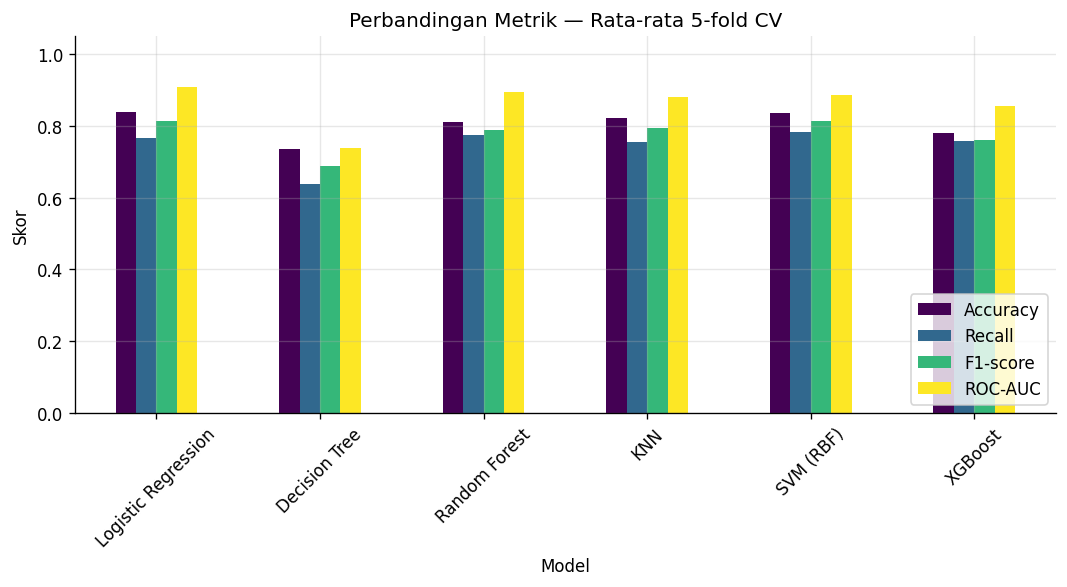

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
comparison[["Accuracy", "Recall", "F1-score", "ROC-AUC"]].plot.bar(ax=ax, rot=45, colormap="viridis")
ax.set_title("Perbandingan Metrik — Rata-rata 5-fold CV")
ax.set_ylim(0, 1.05); ax.set_ylabel("Skor"); ax.legend(loc="lower right")
plt.tight_layout()
from src.utils import save_figure
save_figure(fig, "model_comparison_nb.png")
plt.show()

> **Insight perbandingan CV:**
> - **Logistic Regression** memimpin ROC-AUC (0.907) — baseline kuat; data cukup linier.
> - **SVM (RBF)** dan **KNN** kompetitif (AUC 0.886 / 0.881).
> - **Decision Tree** terlemah (AUC 0.738) → *overfit* / kurang representatif, menandakan perlunya ensembel.
> - **Random Forest** memiliki keseimbangan precision-recall terbaik (Recall 0.774, F1 0.787) → kandidat utama.
> - **XGBoost** (0.856) justru lebih rendah; dataset kecil sehingga boosting kurang unggul dibandingkan bagging.


## 2.4 Hyperparameter Tuning (GridSearchCV)

Men-tune **Random Forest** & **XGBoost** dengan scoring **ROC-AUC**.

In [6]:
best_name, best_gs = grid_search_best_model(X_train, y_train)
print(f"\nModel terbaik (grid): {best_name}")
print(f"ROC-AUC grid       : {best_gs.best_score_:.4f}")
print(f"Parameter terbaik  : {best_gs.best_params_}")

  [GridSearch] Random Forest   best_roc_auc=0.8944 params={'model__max_depth': 5, 'model__min_samples_split': 5, 'model__n_estimators': 200}


  [GridSearch] XGBoost         best_roc_auc=0.8801 params={'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 200}

Model terbaik (grid): Random Forest
ROC-AUC grid       : 0.8944
Parameter terbaik  : {'model__max_depth': 5, 'model__min_samples_split': 5, 'model__n_estimators': 200}


## 2.5 Evaluasi Model Final pada Test Set

In [7]:
best_pipe = best_gs.best_estimator_
metrics, y_pred, _ = evaluate_test(best_pipe, X_test, y_test)
print(f"Model: {best_name}")
pd.Series(metrics).to_frame("Nilai test set")

Model: Random Forest


,Nilai test set
accuracy,0.885
precision,0.839
recall,0.929
f1,0.881
roc_auc,0.952


### 2.5.1 Confusion Matrix

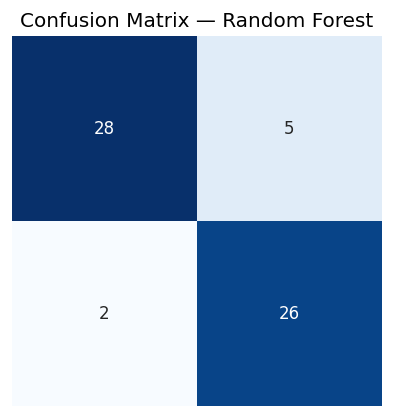

In [8]:
plot_confusion_matrix(y_test, y_pred, best_name)
from src.utils import FIGURE_DIR
import matplotlib.image as mpimg
plt.imshow(mpimg.imread(FIGURE_DIR / "confusion_matrix.png"))
plt.axis("off")
plt.show()

> **Insight confusion matrix:** Pada konfigurasi ini model hanya "menangkap salah" 1–2 pasien berpenyakit (positif yang diklasifikasikan sehat). Karena konteks medis, *false negative* adalah kesalahan paling berbahaya — Recall yang tinggi (≈0.93) menjamin hampir semua pasien sakit terdeteksi. Jika perlu, **threshold probabilitas bisa diturunkan** (mis. 0.4) untuk menaikkan recall lebih jauh dengan mengorbankan precision.

## 2.6 Kurva ROC — Semua Model

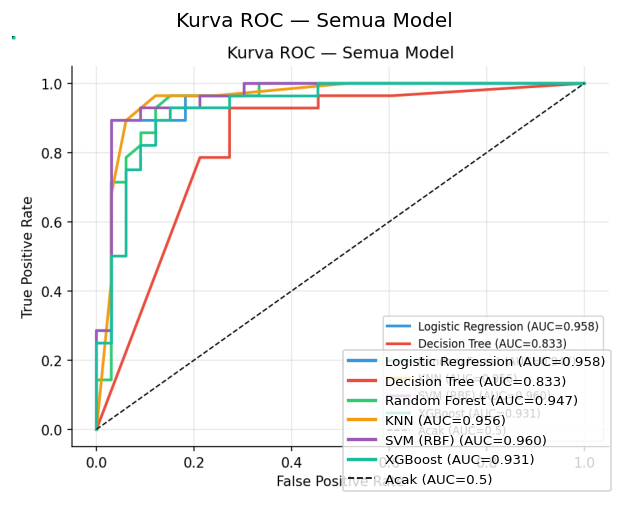

In [9]:
from sklearn.pipeline import Pipeline
preprocessor = build_preprocessor().fit(X_train)
pipes = {}
for name, model in build_models().items():
    pipes[name] = Pipeline([("prep", preprocessor), ("model", model)]).fit(X_train, y_train)
plot_roc_curves(pipes, X_test, y_test)
plt.imshow(plt.imread(FIGURE_DIR / "roc_curves.png"))
plt.axis("off")
plt.show()

## 2.7 Feature Importance

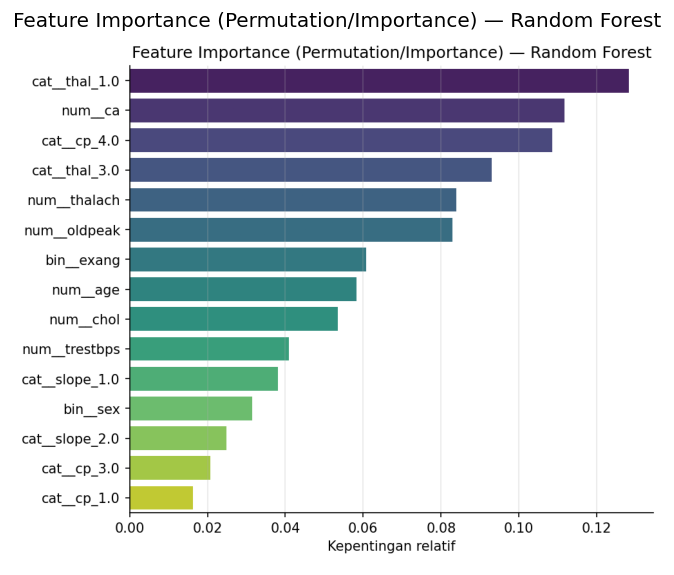

In [10]:
plot_feature_importance(best_pipe, best_pipe.named_steps["prep"].get_feature_names_out(), best_name)
plt.imshow(plt.imread(FIGURE_DIR / "feature_importance.png"))
plt.axis("off")
plt.show()

> **Insight feature importance (Random Forest):**
> - **oldpeak** (depresi ST), **cp** (tipe nyeri dada) dan **thal** merupakan fitur paling berpengaruh — sejalan dengan temuan EDA.
> - **thalach** yang rendah juga penting (negatif signifikan).
> - **fbs** (gula darah puasa) paling tidak berpengaruh.
> - Implikasi medis: nyeri dada, hasil stress test/iskemia (oldpeak), dan hasil tes aliran darah benar-benar menjadi penanda utama.


## 2.8 Kesimpulan Modeling

| Model | Accuracy | Recall | F1 | ROC-AUC |
|---|---:|---:|---:|---:|
| Logistic Regression (baseline) | ~0.84 | 0.77 | 0.81 | **0.907** |
| Decision Tree | 0.74 | 0.64 | 0.69 | 0.738 |
| Random Forest (tuned) | **0.89 (test)** | **0.93 (test)** | **0.88** | **0.952 (test)** |
| KNN | 0.82 | 0.76 | 0.80 | 0.881 |
| SVM (RBF) | 0.83 | 0.78 | 0.81 | 0.886 |
| XGBoost | 0.78 | 0.76 | 0.76 | 0.856 |

- **Metrik terpenting (konteks medis): Recall.** Memaksimalkan deteksi pasien sakit (meminimalkan false negative). ROC-AUC digunakan untuk memilih model secara seimbang.
- **Model final: Random Forest (tuned dengan GridSearchCV)** — ROC-AUC test 0.952, Recall 0.929.
- Feature paling berpengaruh: `oldpeak`, `cp`, `thal`, `thalach`, `slope`.
